Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

Load dataset

In [4]:
df = pd.read_csv("student_learning.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (280, 7)


,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed
0,7.5,54,0,5.6,video,48,0
1,4.4,61,0,6.0,video,50,0
2,8.2,63,1,5.2,group,73,1
3,6.8,64,1,8.4,self,53,0
4,1.3,79,5,5.8,self,51,0


Inspect dataset

In [5]:
# Dataset information
print("Data Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nDataset Description:")
display(df.describe(include="all"))

# Target balance
print("\nTarget Balance:")
print(df["passed"].value_counts())

print("\nTarget Percentage:")
print(df["passed"].value_counts(normalize=True) * 100)

Data Types:
hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method          str
final_score         int64
passed              int64
dtype: object

Missing Values:
hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64

Dataset Description:


,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed
count,280.000000,280.000000,280.000000,280.000000,280,280.000000,280.000000
unique,NaN,NaN,NaN,NaN,3,NaN,NaN
top,NaN,NaN,NaN,NaN,self,NaN,NaN
freq,NaN,NaN,NaN,NaN,141,NaN,NaN
mean,4.882857,76.085714,3.167857,6.651429,NaN,58.228571,0.439286
std,2.580154,13.869843,1.981194,1.336528,NaN,15.613542,0.497189
min,0.600000,52.000000,0.000000,4.500000,NaN,15.000000,0.000000
25%,2.575000,63.750000,2.000000,5.475000,NaN,47.750000,0.000000
50%,4.800000,76.500000,3.000000,6.600000,NaN,59.000000,0.000000
75%,7.200000,89.000000,5.000000,7.800000,NaN,69.250000,1.000000



Target Balance:
passed
0    157
1    123
Name: count, dtype: int64

Target Percentage:
passed
0    56.071429
1    43.928571
Name: proportion, dtype: float64


Visualize target balance

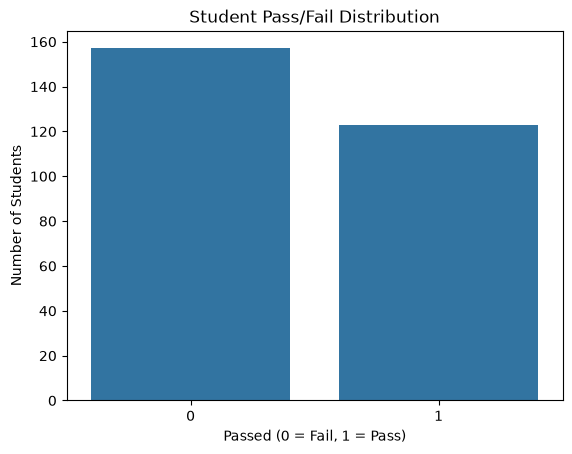

In [6]:
sns.countplot(data=df, x="passed")

plt.title("Student Pass/Fail Distribution")
plt.xlabel("Passed (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")

plt.show()

Select Feature and Target

In [7]:
# Remove target and leakage column
X = df.drop(columns=["passed", "final_score"])

# Target variable
y = df["passed"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Features:
['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method']

Target:
0    0
1    0
2    1
3    0
4    0
Name: passed, dtype: int64


Train/Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (224, 5)
Testing Data: (56, 5)


Preprocessing pipeline

In [9]:
# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numeric Features: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours']
Categorical Features: ['study_method']


C:\Users\786\AppData\Local\Temp\ipykernel_20720\1998232642.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Train Baseline Model

In [10]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline F1 Score:",
      f1_score(y_test, baseline_predictions, zero_division=0))

Baseline Accuracy: 0.5535714285714286
Baseline F1 Score: 0.0


Train Logistic Regression

In [11]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("Logistic Regression F1:",
      f1_score(y_test, logistic_predictions, zero_division=0))

Logistic Regression Accuracy: 0.75
Logistic Regression F1: 0.72


Train Random Forest

In [12]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Random Forest F1:",
      f1_score(y_test, rf_predictions, zero_division=0))

Random Forest Accuracy: 0.7321428571428571
Random Forest F1: 0.7169811320754716


Compare All Model

In [13]:
models = {
    "Dummy Classifier": baseline_predictions,
    "Logistic Regression": logistic_predictions,
    "Random Forest": rf_predictions
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,F1 Score
0,Dummy Classifier,0.553571,0.000000
1,Logistic Regression,0.750000,0.720000
2,Random Forest,0.732143,0.716981


Confusion Matrices

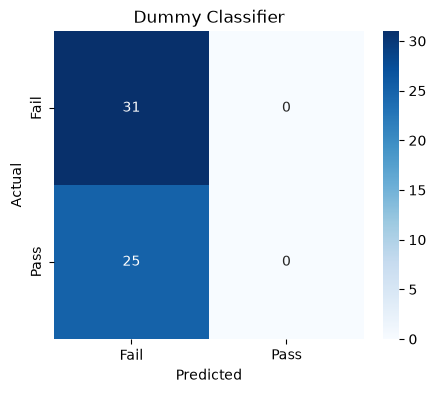

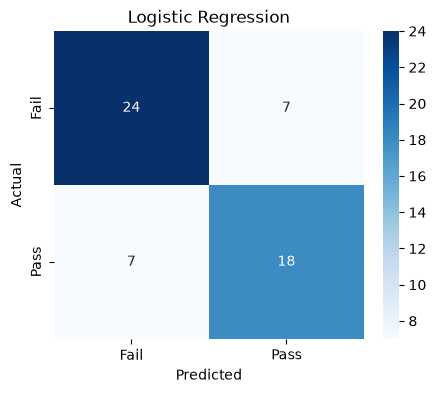

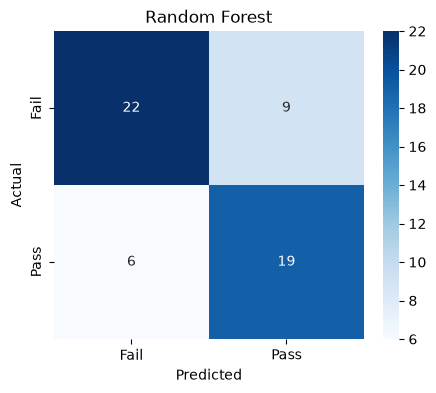

In [14]:
for name, predictions in models.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fail", "Pass"],
        yticklabels=["Fail", "Pass"]
    )

    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

Classification report and error analysis

In [15]:
print("Random Forest Classification Report:")

print(
    classification_report(
        y_test,
        rf_predictions,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

# Find incorrectly predicted records
errors = X_test.copy()

errors["Actual"] = y_test
errors["Predicted"] = rf_predictions

errors = errors[
    errors["Actual"] != errors["Predicted"]
]

print("Incorrect Predictions:")
display(errors)

Random Forest Classification Report:
              precision    recall  f1-score   support

        Fail       0.79      0.71      0.75        31
        Pass       0.68      0.76      0.72        25

    accuracy                           0.73        56
   macro avg       0.73      0.73      0.73        56
weighted avg       0.74      0.73      0.73        56

Incorrect Predictions:


,hours_studied,attendance,practice_tests,sleep_hours,study_method,Actual,Predicted
237,7.6,88,0,5.0,group,0,1
102,2.9,89,6,8.5,video,1,0
188,7.2,59,2,5.2,video,0,1
157,6.4,76,5,8.5,self,0,1
158,7.0,88,0,6.2,self,0,1
86,7.0,89,3,8.2,self,0,1
277,5.0,76,4,6.3,video,0,1
248,3.9,89,6,8.4,video,1,0
196,5.9,73,4,5.8,self,0,1
176,4.4,99,1,6.3,self,1,0


Select best model and save pipeline

In [16]:
candidate_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

best_model_name = max(
    candidate_models,
    key=lambda name: f1_score(
        y_test,
        candidate_models[name].predict(X_test),
        zero_division=0
    )
)

best_model = candidate_models[best_model_name]

print("Best Model:", best_model_name)

joblib.dump(best_model, "student_model.joblib")

print("Model Saved Successfully!")

Best Model: Logistic Regression
Model Saved Successfully!


Reload model and predict new students

In [18]:
loaded_model = joblib.load("student_model.joblib")

new_students = pd.read_csv("new_student_records.csv")

# Remove target or leakage columns if present
new_students = new_students.drop(
    columns=["passed", "final_score"],
    errors="ignore"
)

predictions = loaded_model.predict(new_students)

new_students["Predicted_Pass"] = predictions

new_students["Prediction_Label"] = new_students[
    "Predicted_Pass"
].map({
    0: "Fail",
    1: "Pass"
})

display(new_students)

new_students.to_csv(
    "new_student_predictions.csv",
    index=False
)

,hours_studied,attendance,practice_tests,sleep_hours,study_method,Predicted_Pass,Prediction_Label
0,6.5,90,8,7.5,practice,1,Pass
1,2.0,58,1,5.5,video,0,Fail
2,5.0,80,5,7.0,group,1,Pass
3,8.0,95,9,8.0,self-study,1,Pass
4,3.5,70,3,6.5,video,0,Fail
